In [2]:
import sys, subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'nibabel', 'scipy', 'numpy', 'pandas', 'matplotlib', 'ipywidgets'])


0

In [ ]:
from pathlib import Path
import json, re
import numpy as np
import pandas as pd
import nibabel as nib
from nibabel.processing import resample_from_to
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import display
import ipywidgets as widgets
ROOT = Path("C:/Users/PC/Downloads/TopBrain_Data_Release_Batches1n2nTA36_081726") 
LABEL_FOLDER = "labelsTr_topbrain_v1_mr"
MODALITY = "mr"
assert ROOT.exists(), f'Chưa có dữ liệu tại {ROOT}. Hãy tải, giải nén và sửa ROOT.'


def find_folder(name): ## Hàm tìm kiếm thư mục con có tên name trong ROOT. Nếu tìm thấy nhiều hơn hoặc ít hơn 1 thư mục, sẽ báo lỗi.
    hits = ([ROOT] if ROOT.name == name else []) + [p for p in ROOT.rglob(name) if p.is_dir()]
    if len(hits) != 1:
        raise ValueError(f'Cần đúng một thư mục {name}; tìm thấy {hits}')
    return hits[0]

In [ ]:

### tìm kiếm thư mục ảnh và nhãn, kiểm tra tính hợp lệ của chúng
image_dir = find_folder('imagesTr_topbrain')
label_dir = find_folder(LABEL_FOLDER)
### kiểm tra tính hợp lệ của thư mục ảnh và nhãn
if LABEL_FOLDER.endswith(('_ct', '_mr')):
    assert LABEL_FOLDER.endswith('_' + MODALITY)
### lấy file ảnh theo MODALITY, nếu modality là 'mr', thì sẽ lấy file ảnh có tên 'topcow_mr_*.nii.gz'
images = sorted(image_dir.glob(f'topcow_{MODALITY}_*_0000.nii.gz'))
assert images, 'Không tìm thấy ảnh; kiểm tra tên thư mục và MODALITY.'
print('Số ảnh trong modality đã chọn:', len(images))
print('Thư mục nhãn:', label_dir)

Số ảnh trong modality đã chọn: 25
Thư mục nhãn: C:\Users\PC\Downloads\TopBrain_Data_Release_Batches1n2nTA36_081726\TopBrain_Data_Release_Batches1n2nTA36_081726\labelsTr_topbrain_v1_mr


### 2. Ghép ảnh với nhãn và thống kê hình học

Danh sách ảnh
      ↓
Tìm file nhãn cùng mã ca
      ↓
Kiểm tra ảnh–nhãn có cùng hình học
      ↓
Lưu cặp đường dẫn + thông tin vào bảng

In [5]:
def matching_label(image_path):
    stem = image_path.name.removesuffix('_0000.nii.gz')
    candidates = [label_dir / (stem + '.nii.gz'), label_dir / image_path.name]
    existing = [p for p in candidates if p.exists()]
    if len(existing) != 1:
        raise ValueError(f'Không ghép được duy nhất nhãn cho {image_path.name}: {existing}')
    return existing[0]

pairs, rows = [], []
for p in images:
    q = matching_label(p)
    image, label = nib.load(p), nib.load(q)
    assert len(image.shape) == 3 and len(label.shape) == 3
    same_geometry = image.shape == label.shape and np.allclose(image.affine, label.affine, atol=1e-4, rtol=0)
    spacing = nib.affines.voxel_sizes(image.affine)
    patient_id = re.fullmatch(r'topcow_(?:ct|mr)_(.+)_0000.nii.gz', p.name).group(1)
    rows.append(dict(patient_id=patient_id, modality=MODALITY, image=p.name,
                     shape=image.shape, spacing_x_mm=spacing[0], spacing_y_mm=spacing[1],
                     spacing_z_mm=spacing[2], orientation=''.join(nib.aff2axcodes(image.affine)),
                     same_geometry=same_geometry))
    pairs.append((p, q))
manifest = pd.DataFrame(rows)
display(manifest.head(10))
display(manifest[['spacing_x_mm','spacing_y_mm','spacing_z_mm']].describe())
assert manifest.same_geometry.all(), 'Có ảnh và nhãn lệch hình học; kiểm tra trước khi xử lý.'
print('Trung vị trên bảng này chỉ để quan sát. Trong CV, tính target spacing từ TRAIN của từng fold.')


,patient_id,modality,image,shape,spacing_x_mm,spacing_y_mm,spacing_z_mm,orientation,same_geometry
0,001,mr,topcow_mr_001_0000.nii.gz,"(508, 585, 189)",0.296875,0.296875,0.599994,LPS,True
1,002,mr,topcow_mr_002_0000.nii.gz,"(480, 536, 248)",0.296875,0.296875,0.600002,LPS,True
2,003,mr,topcow_mr_003_0000.nii.gz,"(510, 577, 179)",0.296875,0.296875,0.600000,LPS,True
3,004,mr,topcow_mr_004_0000.nii.gz,"(500, 607, 200)",0.296875,0.296875,0.600002,LPS,True
4,005,mr,topcow_mr_005_0000.nii.gz,"(470, 566, 196)",0.296875,0.296875,0.600001,LPS,True
5,006,mr,topcow_mr_006_0000.nii.gz,"(429, 507, 139)",0.351562,0.351562,0.500001,LPS,True
6,007,mr,topcow_mr_007_0000.nii.gz,"(490, 561, 200)",0.296875,0.296875,0.599996,LPS,True
7,008,mr,topcow_mr_008_0000.nii.gz,"(485, 592, 181)",0.296875,0.296875,0.599997,LPS,True
8,010,mr,topcow_mr_010_0000.nii.gz,"(459, 556, 194)",0.296875,0.296875,0.599999,LPS,True
9,011,mr,topcow_mr_011_0000.nii.gz,"(470, 581, 153)",0.296875,0.296875,0.600000,LPS,True


,spacing_x_mm,spacing_y_mm,spacing_z_mm
count,25.000000,25.000000,25.000000
mean,0.299062,0.299062,0.595999
std,0.010938,0.010937,0.020000
min,0.296875,0.296875,0.500001
25%,0.296875,0.296875,0.599997
50%,0.296875,0.296875,0.599998
75%,0.296875,0.296875,0.600000
max,0.351562,0.351562,0.600004


Trung vị trên bảng này chỉ để quan sát. Trong CV, tính target spacing từ TRAIN của từng fold.


### Đọc từ điển nhãn trước khi gọi tên mạch

In [6]:
json_files = sorted((ROOT).rglob('*.json'))
print('Các JSON:', [str(p.relative_to(ROOT)) for p in json_files])
# Chọn đúng file sau khi đọc tên:
LABELMAP_FILE = None  # Ví dụ: json_files[0], sau khi xác nhận đúng schema
if LABELMAP_FILE is not None:
    labelmap = json.loads(Path(LABELMAP_FILE).read_text(encoding='utf-8'))
    print(json.dumps(labelmap, ensure_ascii=False, indent=2)[:8000])


Các JSON: ['TopBrain_Data_Release_Batches1n2nTA36_081726\\labelmap_jsons\\labels_topbrain_v1_ct.json', 'TopBrain_Data_Release_Batches1n2nTA36_081726\\labelmap_jsons\\labels_topbrain_v1_mr.json', 'TopBrain_Data_Release_Batches1n2nTA36_081726\\labelmap_jsons\\labels_topbrain_v2_topaneu36class.json']


### Chọn một ca thật
Chưa có bất kỳ chuẩn hóa, lọc hay resampling nào. So sánh hình gốc trước.
as_closest_canonical sắp xếp lại các trục và cập nhật affine; không đăng ký CTA với MRA.
Các lát dưới đây theo trục mảng gần R/A/S; nếu ảnh có góc nghiêng, chúng không phải mặt phẳng giải phẫu chuẩn tuyệt đối.

In [18]:
CASE_INDEX = 0  # SỬA để chọn ca
original_image = nib.load(pairs[CASE_INDEX][0])
original_label = nib.load(pairs[CASE_INDEX][1])
image_ras = nib.as_closest_canonical(original_image)
label_ras = nib.as_closest_canonical(original_label)
image = image_ras.get_fdata(dtype=np.float32)
raw_label = np.asanyarray(label_ras.dataobj)
assert np.isfinite(image).all() and np.isfinite(raw_label).all()
assert np.allclose(raw_label, np.rint(raw_label)) and raw_label.min() >= 0
label = np.rint(raw_label).astype(np.int32)
assert image.shape == label.shape and np.allclose(image_ras.affine, label_ras.affine)
spacing = nib.affines.voxel_sizes(image_ras.affine)
ids, counts = np.unique(label, return_counts=True)
class_counts = pd.DataFrame({'label_id': ids, 'voxels': counts})
class_counts['volume_mm3'] = class_counts.voxels * np.prod(spacing)
display(class_counts)
print('Ca:', pairs[CASE_INDEX][0].name)
print('Spacing (mm):', spacing, '| Axes:', nib.aff2axcodes(image_ras.affine))
print('Tỷ lệ voxel có nhãn mạch:', float(np.mean(label > 0)))

print("Ảnh:", pairs[CASE_INDEX][0])
print("Nhãn:", pairs[CASE_INDEX][1])


,label_id,voxels,volume_mm3
0,0,55877166,2.954804e+06
1,1,8407,4.445650e+02
2,2,5043,2.666756e+02
3,3,5886,3.112537e+02
4,4,58072,3.070867e+03
5,5,2321,1.227353e+02
6,6,57643,3.048182e+03
7,7,5897,3.118354e+02
8,8,773,4.087651e+01
9,11,4748,2.510759e+02


Ca: topcow_mr_001_0000.nii.gz
Spacing (mm): [0.29687499 0.29687499 0.59999418] | Axes: ('R', 'A', 'S')
Tỷ lệ voxel có nhãn mạch: 0.00516057287710831
Ảnh: C:\Users\PC\Downloads\TopBrain_Data_Release_Batches1n2nTA36_081726\TopBrain_Data_Release_Batches1n2nTA36_081726\imagesTr_topbrain\topcow_mr_001_0000.nii.gz
Nhãn: C:\Users\PC\Downloads\TopBrain_Data_Release_Batches1n2nTA36_081726\TopBrain_Data_Release_Batches1n2nTA36_081726\labelsTr_topbrain_v1_mr\topcow_mr_001.nii.gz


### Xem ảnh, nhãn và ảnh chồng nhãn
Kéo thanh để theo mạch qua nhiều lát; đổi hướng để tránh kết luận từ một lát.
Chọn label 0 để xem tất cả mạch, hoặc một mã để cô lập đúng mạch đó.
Các màu chỉ để phân biệt ID; chưa phải tên giải phẫu.

In [ ]:
max_id = int(label.max())
colors = plt.get_cmap('turbo')(np.linspace(0, 1, max_id + 1))
colors[0] = (0, 0, 0, 0)
cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(-0.5, max_id + 1.5), cmap.N)
limits = np.percentile(image[np.isfinite(image)], [1, 99.5])

def plane(array, axis, index):
    return np.take(array, index, axis=axis).T

def view(axis=2, fraction=0.5, label_id=0):
    index = min(int(round(fraction * (image.shape[axis] - 1))), image.shape[axis] - 1)
    img2d, lab2d = plane(image, axis, index), plane(label, axis, index)
    keep = lab2d > 0 if label_id == 0 else lab2d == label_id
    overlay = np.ma.masked_where(~keep, lab2d)
    axes_left = [a for a in range(3) if a != axis]
    aspect = spacing[axes_left[1]] / spacing[axes_left[0]]
    fig, axs = plt.subplots(1, 3, figsize=(14, 5))
    for ax in (axs[0], axs[2]):
        ax.imshow(img2d, cmap='gray', origin='lower', aspect=aspect,
                  vmin=limits[0], vmax=limits[1], interpolation='nearest')
    axs[1].imshow(overlay, cmap=cmap, norm=norm, origin='lower', aspect=aspect, interpolation='nearest')
    axs[2].imshow(overlay, cmap=cmap, norm=norm, origin='lower', aspect=aspect,
                  interpolation='nearest', alpha=0.55)
    for ax, title in zip(axs, ['Image', 'Reference labels', 'Overlay']):
        ax.set_title(title); ax.axis('off')
    fig.suptitle(f'Array axis {axis} | slice {index} | selected label {label_id}')
    plt.tight_layout(); plt.show()

widgets.interact(view,
    axis=widgets.Dropdown(options=[('Axis 0: approximately sagittal',0),
                                   ('Axis 1: approximately coronal',1),
                                   ('Axis 2: approximately axial',2)], value=2),
    fraction=widgets.FloatSlider(value=0.5,min=0,max=1,step=0.01,continuous_update=False),
    label_id=widgets.Dropdown(options=[('All vessels',0)] + [(str(int(i)),int(i)) for i in ids if i != 0]))


interactive(children=(Dropdown(description='axis', index=2, options=(('Axis 0: approximately sagittal', 0), ('…

<function __main__.view(axis=2, fraction=0.5, label_id=0)>

### Resample ảnh và nhãn về CÙNG một lưới
TARGET_MM mặc định là spacing của ca đã chọn (không đổi). Sau khi xem thống kê,
thử một spacing phù hợp. Đây là thí nghiệm quan sát, không chọn thông số tối ưu cho cả dataset.
Giữ hướng trục của ảnh và giữ góc ngoài thấp của khối ảnh; làm tròn kích thước để phủ vùng gốc.
Ảnh dùng nội suy tuyến tính, nhãn dùng nearest-neighbor. Lưới mới có thể rộng thêm dưới một ô mỗi trục.
Downsampling có thể làm mất mạch nhỏ dù các mã nhãn vẫn hợp lệ.

In [10]:
TARGET_MM = tuple(float(v) for v in spacing)  # SỬA sau khi quan sát; không mặc định ép 1 mm
assert len(TARGET_MM) == 3 and np.all(np.asarray(TARGET_MM) > 0)

def target_grid(source, target_spacing):
    old_spacing = nib.affines.voxel_sizes(source.affine)
    new_affine = source.affine.copy()
    new_affine[:3, :3] = source.affine[:3, :3] @ np.diag(np.asarray(target_spacing) / old_spacing)
    new_affine[:3, 3] = source.affine[:3, 3] + 0.5 * (new_affine[:3,:3] - source.affine[:3,:3]).sum(axis=1)
    new_shape = tuple(np.ceil(np.asarray(source.shape) * old_spacing / target_spacing).astype(int))
    return new_shape, new_affine

grid = target_grid(image_ras, TARGET_MM)
resampled_image = resample_from_to(image_ras, grid, order=1, mode='constant', cval=float(image.min()))
resampled_label = resample_from_to(label_ras, grid, order=0, mode='constant', cval=0)
after_label = np.rint(np.asanyarray(resampled_label.dataobj)).astype(np.int32)
assert resampled_image.shape == resampled_label.shape
assert np.allclose(resampled_image.affine, resampled_label.affine)
assert set(np.unique(after_label)).issubset(set(ids) | {0})
lost = sorted(set(ids) - set(np.unique(after_label)) - {0})
print('Trước:', image_ras.shape, spacing)
print('Sau:', resampled_image.shape, nib.affines.voxel_sizes(resampled_image.affine))
print('Các lớp biến mất sau resampling:', lost)
if lost:
    print('Hãy kiểm tra mạch nhỏ và chọn lại spacing. Mã hợp lệ không có nghĩa giải phẫu được giữ nguyên.')

before_counts = dict(zip(ids.tolist(), counts.tolist()))
new_ids, new_counts = np.unique(after_label, return_counts=True)
after_counts = dict(zip(new_ids.tolist(), new_counts.tolist()))
rows = []
for class_id in ids:
    if class_id == 0: continue
    before_mm3 = before_counts[int(class_id)] * np.prod(spacing)
    after_mm3 = after_counts.get(int(class_id), 0) * np.prod(TARGET_MM)
    rows.append({'label_id': int(class_id), 'before_mm3': before_mm3,
                 'after_mm3': after_mm3, 'change_percent': 100 * (after_mm3 / before_mm3 - 1)})
display(pd.DataFrame(rows))


Trước: (508, 585, 189) [0.29687499 0.29687499 0.59999418]
Sau: (508, 585, 189) [0.29687499 0.29687499 0.59999418]
Các lớp biến mất sau resampling: []


,label_id,before_mm3,after_mm3,change_percent
0,1,444.565047,444.565047,0.000000
1,2,266.675572,266.675572,0.000000
2,3,311.253701,311.253701,0.000000
3,4,3070.867299,3058.281778,-0.409836
4,5,122.735277,122.735277,0.000000
5,6,3048.181632,3031.735845,-0.539528
6,7,311.835385,311.835385,0.000000
7,8,40.876505,40.876505,0.000000
8,11,251.075870,251.075870,0.000000
9,12,224.054015,224.054015,0.000000


### So sánh trên cùng vị trí vật lý
Đưa ảnh/nhãn đã resample trở lại lưới gốc CHỈ để xem tác động của vòng resampling.
Đây không phải dự đoán của mô hình. Chọn lát có mạch thay vì chỉ nhìn lát giữa.

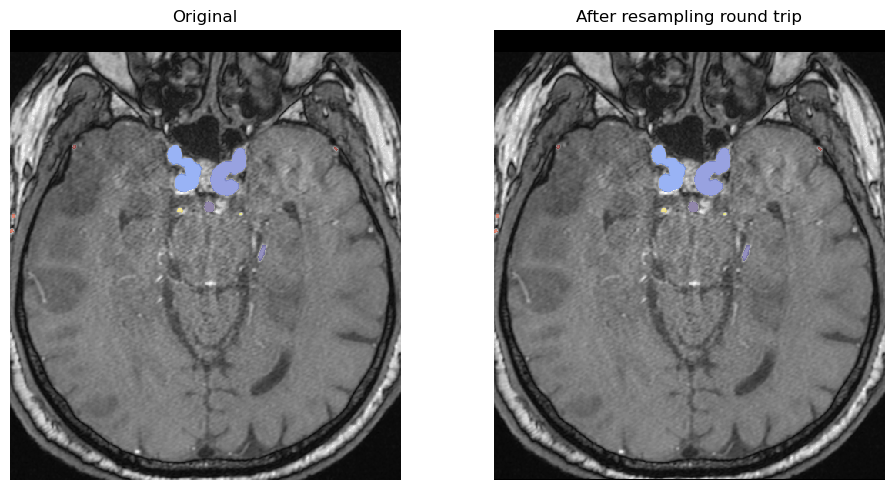

In [11]:
back_image = resample_from_to(resampled_image, image_ras, order=1, cval=float(image.min())).get_fdata(dtype=np.float32)
back_label = np.rint(np.asanyarray(resample_from_to(resampled_label, label_ras, order=0).dataobj)).astype(np.int32)
AXIS = 2
slice_counts = (label > 0).sum(axis=tuple(a for a in range(3) if a != AXIS))
INDEX = int(np.argmax(slice_counts))  # SỬA để kiểm tra vùng khác
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
remaining = [a for a in range(3) if a != AXIS]
aspect = spacing[remaining[1]] / spacing[remaining[0]]
for ax, img3d, lab3d, title in zip(axs, [image,back_image], [label,back_label],
                                  ['Original', 'After resampling round trip']):
    ax.imshow(plane(img3d,AXIS,INDEX), cmap='gray', origin='lower', aspect=aspect,
              vmin=limits[0], vmax=limits[1], interpolation='nearest')
    labels2d = plane(lab3d,AXIS,INDEX)
    ax.imshow(np.ma.masked_where(labels2d == 0, labels2d), cmap=cmap, norm=norm,
              origin='lower', aspect=aspect, interpolation='nearest', alpha=0.55)
    ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()
